In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from matplotlib.patches import Patch
import matplotlib.patches as mpatches
from matplotlib.legend_handler import HandlerLine2D
from matplotlib.ticker import MultipleLocator, FixedLocator
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool
import pandas as pd
import pickle
import scipy
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple#, HandlerTupleVertical

#from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

In [22]:
# load mpsi=0.1GeV
with open('pickled/mcmc_0.001_128_40000_fx0.1_mpsi0.1_2024-11-15_07-21-25.pkl', 'rb') as h:
    mcmc_output_01_01 = pickle.load(h)

In [23]:
#load mpsi=1e-5 GeV
with open('pickled/mcmc_0.001_64_40000_fx0.1_mpsi1e-05_2024-11-14_20-50-03.pkl', 'rb') as h:
    mcmc_output_01_1e_5 = pickle.load(h)

In [24]:
# load mpsi=mx
with open('pickled/mcmc_0.001_64_40000_fx0.1_2024-11-13_08-07-26.pkl', 'rb') as h:
    mcmc_output_01 = pickle.load(h)

In [6]:
with open('data/prior_boundary_points.pkl', 'rb') as f:
    data = pickle.load(f)

# Unpack the dictionary into variables
mchi_values = data['mchi']
s0_max = data['max_s0']

In [9]:
def plot_constraint(mcmc_output, color, label, shaded=False, fx=1):
    # plot equal mass case
    samples_coords = np.array([[x, y] for y, x in mcmc_output])

    # Reshape to get a 2D array of samples
    x_samples = samples_coords[:,0]
    y_samples = samples_coords[:,1]

    # Create a 2D histogram
    nbins = 50
    H, xedges, yedges = np.histogram2d(x_samples, y_samples, bins=nbins, density=True)

    # Apply Gaussian smoothing
    sigma = 3.5
    H_smooth = scipy.ndimage.gaussian_filter(H, sigma=sigma)

    # Compute the bin centers
    xcenters = (xedges[:-1] + xedges[1:]) / 2
    ycenters = (yedges[:-1] + yedges[1:]) / 2

    # Create a meshgrid for the centers
    X, Y = np.meshgrid(xcenters, ycenters)

    # Flatten the smoothed histogram and sort the values
    H_smooth_flat = H_smooth.flatten()
    H_smooth_sorted = np.sort(H_smooth_flat)

    # Calculate the cumulative distribution function (CDF)
    cdf = np.cumsum(H_smooth_sorted)
    cdf /= cdf[-1]  # Normalize


    # Find the 95th percentile value
    percentile_value = np.percentile(H_smooth, 5)

    # Generate the contour plot
    #plt.figure(dpi=450)#(figsize=(8, 6))
    contour = plt.contour(X, Y, H_smooth.T, levels=[percentile_value],colors=color, linewidths=1.5)


    path = contour.collections[0].get_paths()[0]
    v = path.vertices
    x = v[:,0]
    y = v[:,1]

    #y2=-24
    plt.plot(x, y, label=label, color=color)
    if shaded:
        y2 = np.interp(x, np.log10(mchi_values), np.log10(s0_max/fx))
        plt.plot(np.log10(mchi_values), np.log10(s0_max/fx), color=color, linewidth=1.5)
        plt.fill_between(x, y, y2, where=(y2 >= y), interpolate=True, color=color, alpha=0.3,)


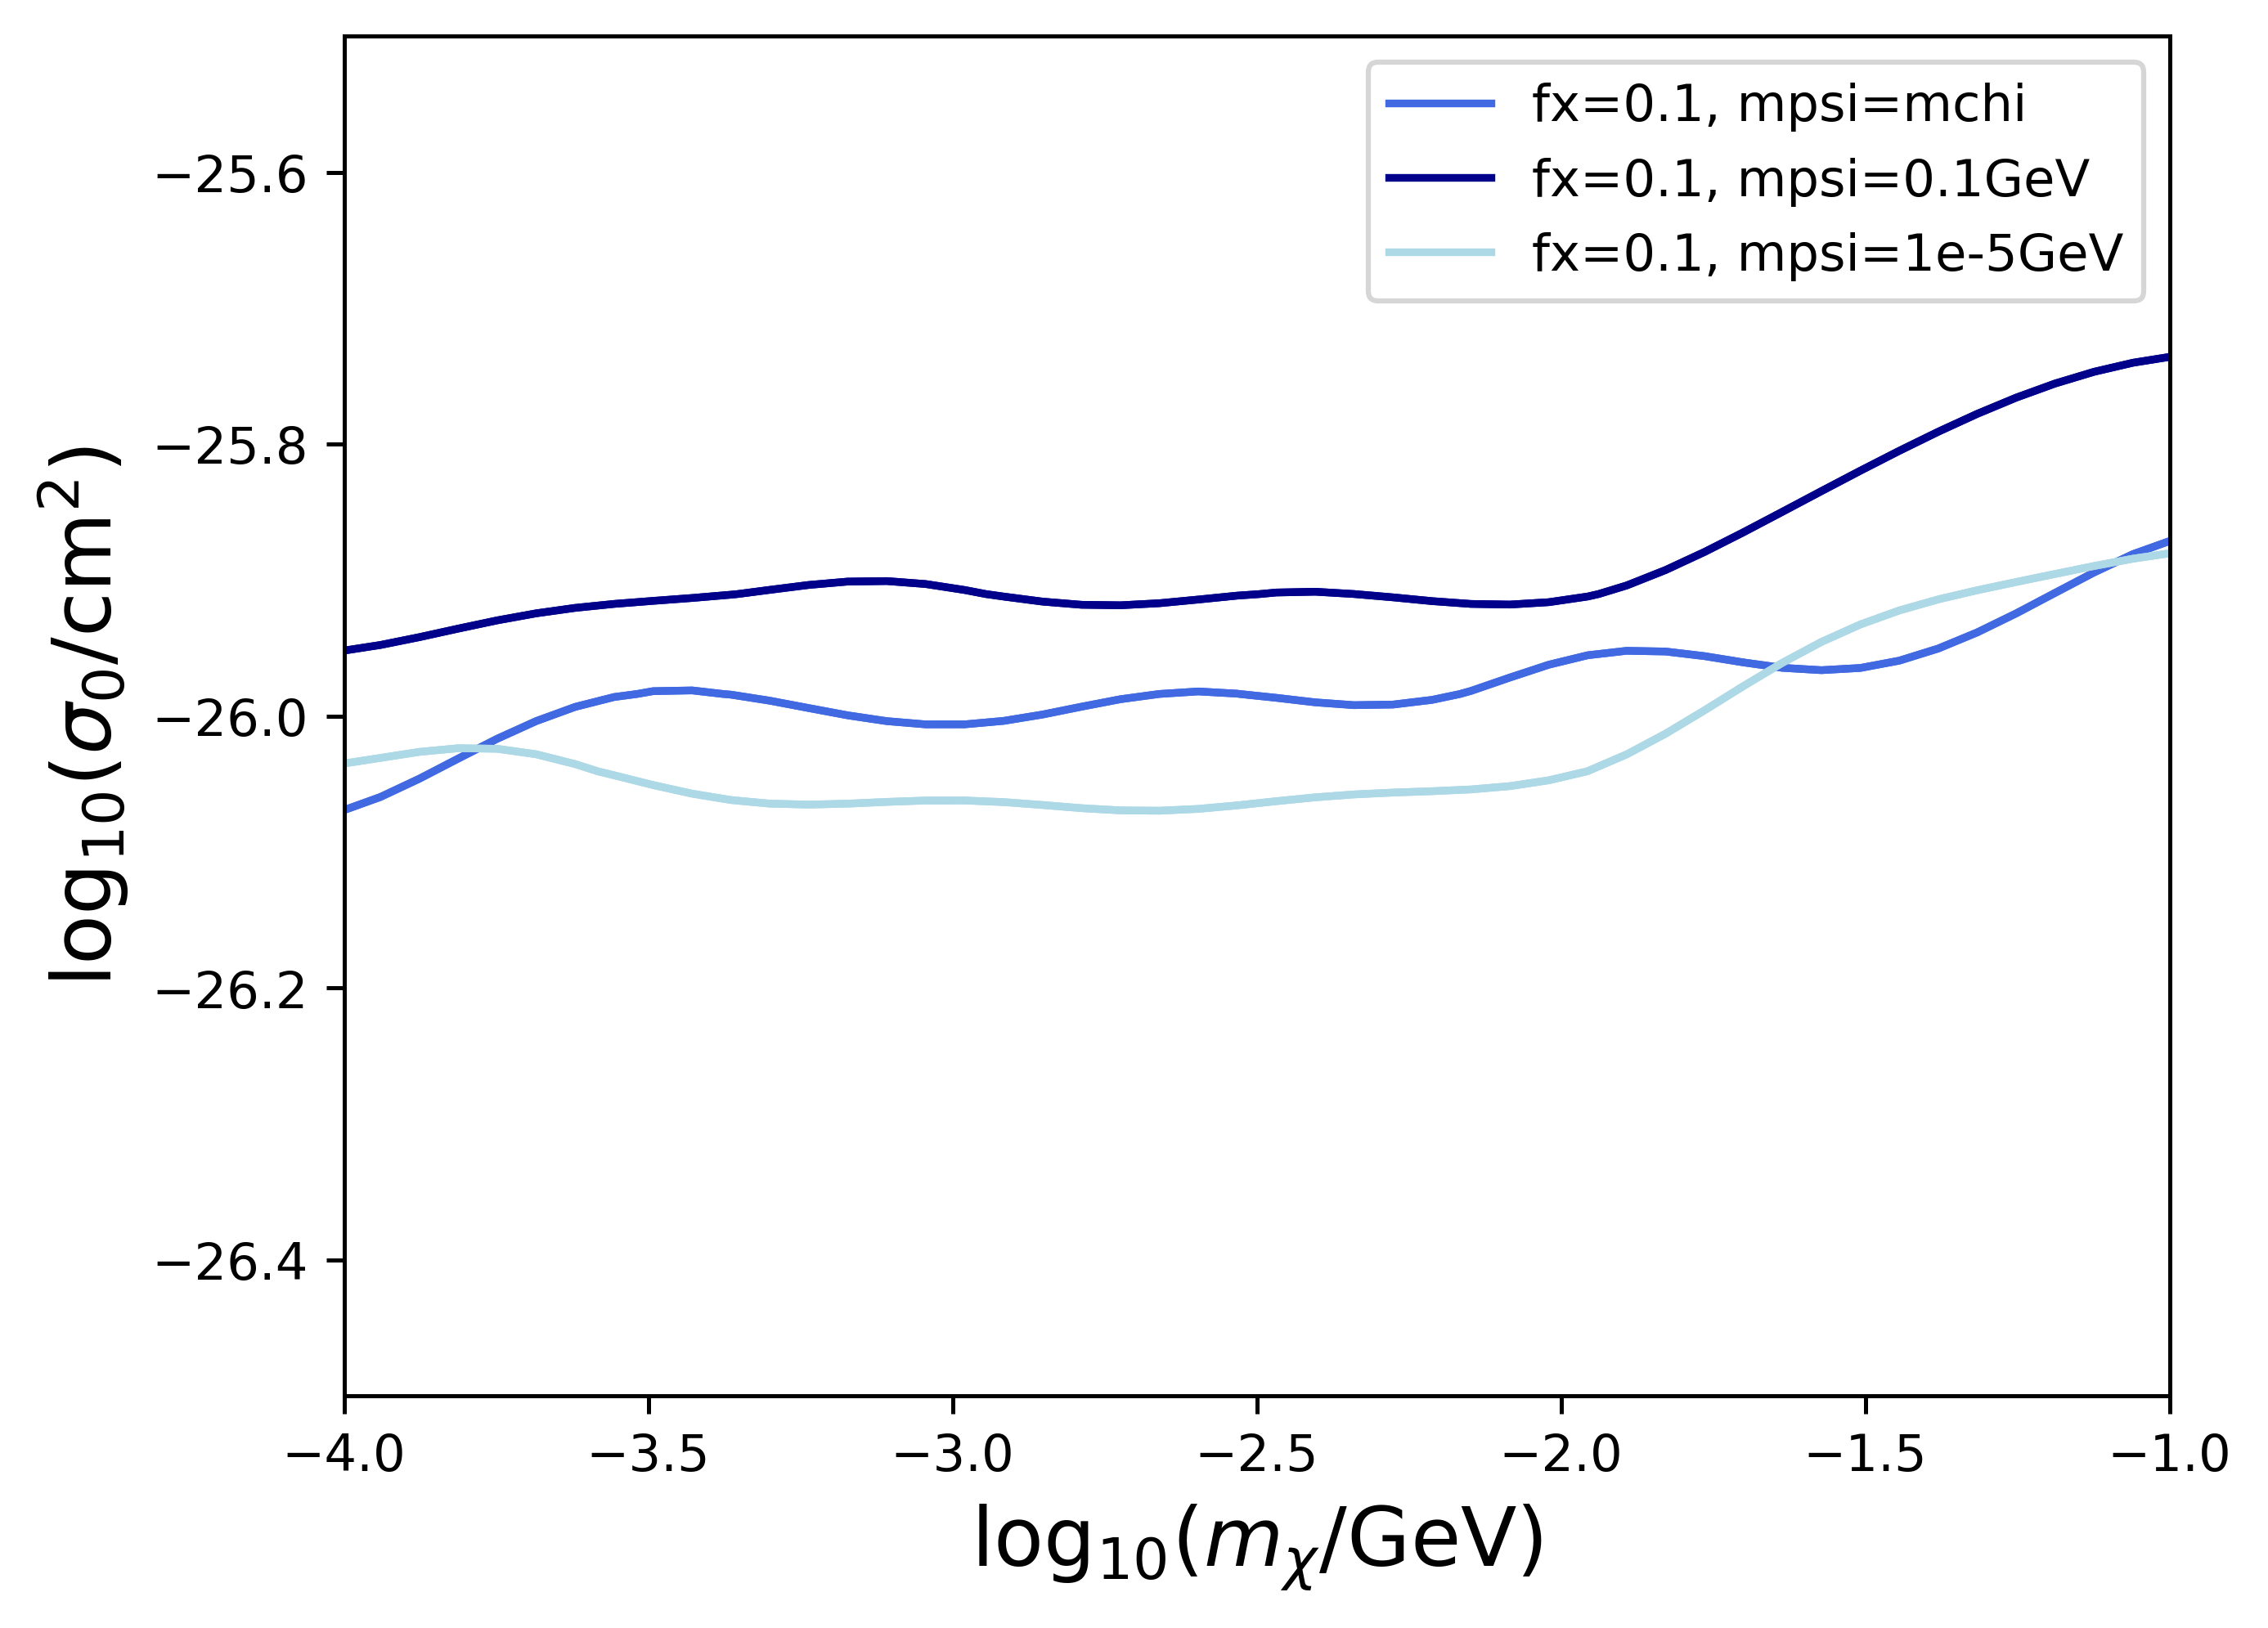

In [25]:
# plot equal mass case  
plt.figure(dpi=450)
plot_constraint(mcmc_output_01, 'royalblue', 'fx=0.1, mpsi=mchi', shaded=False, fx=0.1)

plot_constraint(mcmc_output_01_01, 'darkblue', 'fx=0.1, mpsi=0.1GeV', shaded=False, fx=0.1)  
plot_constraint(mcmc_output_01_1e_5, 'lightblue', 'fx=0.1, mpsi=1e-5GeV', shaded=False, fx=0.1) 

plt.xlim(-4, -1)
plt.ylim(-26.5, -25.5)
        
plt.xlabel(r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$", size=16)
plt.ylabel(r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", size=16)
plt.legend()
        